In [2]:
# ============================================================
# EXPERIMENT 2 - CELL 3
# Register Foggy Cityscapes for Adaptive Teacher
# Reuses the environment already initialized above
# ============================================================

from pathlib import Path
from copy import deepcopy
from collections import Counter

from detectron2.data import DatasetCatalog, MetadataCatalog

DATA_ROOT = Path("/workspace/datasets")

SOURCE_TRAIN = "cityscapes_fine_instance_seg_train"
SOURCE_VAL = "cityscapes_fine_instance_seg_val"

TARGET_TRAIN = "cityscapes_foggy_train"
TARGET_VAL = "cityscapes_foggy_val"

BETA = 0.02  # Strong fog for initial target-domain experiment

assert SOURCE_TRAIN in DatasetCatalog.list(), (
    f"Source dataset not registered: {SOURCE_TRAIN}"
)

assert SOURCE_VAL in DatasetCatalog.list(), (
    f"Validation dataset not registered: {SOURCE_VAL}"
)

# ------------------------------------------------------------
# 1. Find Foggy Cityscapes images
# ------------------------------------------------------------

def foggy_images(split, beta):

    matches = [
        p for p in DATA_ROOT.rglob("*.png")
        if f"foggy_beta_{beta}" in p.name
        and split in p.parts
    ]

    if not matches:
        raise FileNotFoundError(
            f"No foggy images found: split={split}, beta={beta}"
        )

    return sorted(matches)


train_paths = foggy_images("train", BETA)
val_paths = foggy_images("val", BETA)

print("Foggy training images:", len(train_paths))
print("Foggy validation images:", len(val_paths))

# ------------------------------------------------------------
# 2. Match clear and foggy images by Cityscapes image ID
# ------------------------------------------------------------

def canonical_name(path):

    name = Path(path).name

    name = name.replace("_leftImg8bit", "")
    name = name.replace(f"_foggy_beta_{BETA}", "")

    return name


def build_foggy_dataset(source_name, fog_paths, unlabeled):

    source_records = DatasetCatalog.get(source_name)

    source_index = {}

    for record in source_records:
        key = canonical_name(record["file_name"])

        if key in source_index:
            raise RuntimeError(f"Duplicate source key: {key}")

        source_index[key] = record

    output = []
    unmatched = []

    for fog_path in fog_paths:

        key = canonical_name(fog_path)

        source_record = source_index.get(key)

        if source_record is None:
            unmatched.append(str(fog_path))
            continue

        item = deepcopy(source_record)
        item["file_name"] = str(fog_path)

        if unlabeled:
            item.pop("annotations", None)
            item.pop("sem_seg_file_name", None)

        output.append(item)

    print(
        f"{source_name}: matched={len(output)}, "
        f"unmatched={len(unmatched)}"
    )

    if unmatched:
        print("First unmatched images:")
        for path in unmatched[:5]:
            print(" ", path)

    if len(output) != len(fog_paths):
        raise RuntimeError(
            "Some foggy images could not be matched. "
            "Check filenames before training."
        )

    return output


target_train_records = build_foggy_dataset(
    SOURCE_TRAIN,
    train_paths,
    unlabeled=True
)

target_val_records = build_foggy_dataset(
    SOURCE_VAL,
    val_paths,
    unlabeled=False
)

# ------------------------------------------------------------
# 3. Register datasets
# ------------------------------------------------------------

if TARGET_TRAIN not in DatasetCatalog.list():

    DatasetCatalog.register(
        TARGET_TRAIN,
        lambda records=target_train_records: records
    )

if TARGET_VAL not in DatasetCatalog.list():

    DatasetCatalog.register(
        TARGET_VAL,
        lambda records=target_val_records: records
    )

source_meta = MetadataCatalog.get(SOURCE_TRAIN)

for name in [TARGET_TRAIN, TARGET_VAL]:

    MetadataCatalog.get(name).set(
        thing_classes=list(source_meta.thing_classes),
        evaluator_type="coco"
    )

# ------------------------------------------------------------
# 4. Validate source and target
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ADAPTIVE TEACHER DATASET VALIDATION")
print("=" * 65)

for name in [SOURCE_TRAIN, TARGET_TRAIN, TARGET_VAL]:

    records = DatasetCatalog.get(name)

    print(f"\n{name}")
    print("Images:", len(records))
    print("Example:", records[0]["file_name"])
    print(
        "Has annotations:",
        "annotations" in records[0]
    )

assert len(target_train_records) > 0
assert len(target_val_records) > 0

assert all(
    "annotations" not in r
    for r in target_train_records
)

assert any(
    len(r.get("annotations", [])) > 0
    for r in target_val_records
)

print("\nDataset registration successful.")
print("Target training: unlabeled")
print("Target validation: labeled for evaluation")


Foggy training images: 2975
Foggy validation images: 500
cityscapes_fine_instance_seg_train: matched=2975, unmatched=0
cityscapes_fine_instance_seg_val: matched=500, unmatched=0

ADAPTIVE TEACHER DATASET VALIDATION

cityscapes_fine_instance_seg_train
Images: 2975
Example: /workspace/datasets/cityscapes/leftImg8bit/train/aachen/aachen_000000_000019_leftImg8bit.png
Has annotations: True

cityscapes_foggy_train
Images: 2975
Example: /workspace/datasets/cityscapes_foggy/leftImg8bit/train/aachen/aachen_000000_000019_leftImg8bit_foggy_beta_0.02.png
Has annotations: False

cityscapes_foggy_val
Images: 500
Example: /workspace/datasets/cityscapes_foggy/leftImg8bit/val/frankfurt/frankfurt_000000_000294_leftImg8bit_foggy_beta_0.02.png
Has annotations: True

Dataset registration successful.
Target training: unlabeled
Target validation: labeled for evaluation


In [4]:

import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/workspace")
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"
PILOT = ROOT / "experiments/cityscapes_to_foggy/source_only/pilot_1000_v1"
RUN = ROOT / "experiments/cityscapes_to_foggy/adaptive_teacher/smoke_100_v1"
CONFIG_PATH = RUN / "adaptive_teacher_smoke_100.yaml"

diagnostic_code = r'''
import sys
from detectron2.config import get_cfg
from detectron2.data import DatasetCatalog

from adapteacher import add_ateacher_config
import adapteacher.modeling
import adapteacher.data.datasets.builtin

from register_foggy_datasets import register

register()

cfg = get_cfg()
add_ateacher_config(cfg)
cfg.merge_from_file(sys.argv[1])

print("\n--- TRAINER ---")
print("Actual trainer:", repr(cfg.SEMISUPNET.Trainer))
print("Expected trainer:", repr("ateacher"))
print("Trainer matches:", cfg.SEMISUPNET.Trainer == "ateacher")

print("\n--- DATASET REGISTRATION ---")
names = (
    *cfg.DATASETS.TRAIN_LABEL,
    *cfg.DATASETS.TRAIN_UNLABEL,
    *cfg.DATASETS.TEST
)

for name in names:
    print(name, "registered:", name in DatasetCatalog.list())

print("\n--- TARGET TRAINING DATA ---")
target = DatasetCatalog.get(cfg.DATASETS.TRAIN_UNLABEL[0])

print("Number of images:", len(target))
print("Expected:", 2975)
print("Count matches:", len(target) == 2975)

print("First record keys:", list(target[0].keys()))
print("First image:", target[0]["file_name"])

with_annotations = [
    i for i, record in enumerate(target)
    if "annotations" in record
]

print("Records with annotations key:", len(with_annotations))
print("Expected:", 0)

if with_annotations:
    print("First affected index:", with_annotations[0])
    print("Annotations:", target[with_annotations[0]].get("annotations", [])[:2])

print("\n--- VALIDATION DATA ---")
validation = DatasetCatalog.get(cfg.DATASETS.TEST[0])
print("Validation images:", len(validation))
print("Validation record keys:", list(validation[0].keys()))
print("Has annotations:", "annotations" in validation[0])

print("\nDIAGNOSTIC COMPLETED")
'''

env = os.environ.copy()
env["DETECTRON2_DATASETS"] = str(ROOT / "datasets")
env["PYTHONPATH"] = os.pathsep.join([
    str(RUN),
    str(PILOT / "python_compat"),
    str(REPO),
    env.get("PYTHONPATH", "")
])

result = subprocess.run(
    [
        sys.executable,
        "-c",
        diagnostic_code,
        str(CONFIG_PATH)
    ],
    cwd=str(ROOT),
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("STDERR:\n", result.stderr)

print("Return code:", result.returncode)


Registered target datasets: 2975 training, 500 validation

--- TRAINER ---
Actual trainer: 'ateacher'
Expected trainer: 'ateacher'
Trainer matches: True

--- DATASET REGISTRATION ---
cityscapes_fine_instance_seg_train registered: True
cityscapes_foggy_train registered: True
cityscapes_foggy_val registered: True

--- TARGET TRAINING DATA ---
Number of images: 8925
Expected: 2975
Count matches: False
First record keys: ['file_name', 'image_id', 'height', 'width', 'annotations']
First image: /workspace/datasets/cityscapes_foggy/leftImg8bit/train/aachen/aachen_000000_000019_leftImg8bit_foggy_beta_0.005.png
Records with annotations key: 8925
Expected: 0
First affected index: 0
Annotations: [{'iscrowd': np.False_, 'category_id': 0, 'bbox': (np.int64(892), np.int64(446), np.int64(912), np.int64(497)), 'bbox_mode': <BoxMode.XYXY_ABS: 0>, 'segmentation': {'size': [1024, 2048], 'counts': b'f^lk0f0Wo08C800O100N2K5N3NEgQOQOXn0m0nQOPOQn0P1RROnNnm0Q1TROnNlm0Q1c0TOSQOc0nn0YOVQOe0To0N2N3M2O1Dma^S1'}},

In [5]:

# ============================================================
# EXPERIMENT 2 - CELL 6
# Fix conflicting Foggy Cityscapes registrations
# No GPU training
# ============================================================

import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/workspace")
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"
PILOT = ROOT / "experiments/cityscapes_to_foggy/source_only/pilot_1000_v1"
RUN = ROOT / "experiments/cityscapes_to_foggy/adaptive_teacher/smoke_100_v1"

REGISTRATION_FILE = RUN / "register_foggy_datasets.py"
CONFIG_PATH = RUN / "adaptive_teacher_smoke_100.yaml"

assert REGISTRATION_FILE.exists()
assert CONFIG_PATH.exists()

# ------------------------------------------------------------
# 1. Patch the existing registration module
# ------------------------------------------------------------

code = REGISTRATION_FILE.read_text()

old = '''    if TARGET_TRAIN not in DatasetCatalog.list():
        DatasetCatalog.register(
            TARGET_TRAIN,
            lambda records=train_records: records
        )

    if TARGET_VAL not in DatasetCatalog.list():
        DatasetCatalog.register(
            TARGET_VAL,
            lambda records=val_records: records
        )'''

new = '''    # Override previously registered all-density datasets.
    for name in (TARGET_TRAIN, TARGET_VAL):
        if name in DatasetCatalog.list():
            DatasetCatalog.remove(name)
            MetadataCatalog.remove(name)

    DatasetCatalog.register(
        TARGET_TRAIN,
        lambda records=train_records: records
    )

    DatasetCatalog.register(
        TARGET_VAL,
        lambda records=val_records: records
    )'''

if old in code:
    code = code.replace(old, new)
    REGISTRATION_FILE.write_text(code)
    print("Registration module patched successfully.")
elif new in code:
    print("Registration module already patched.")
else:
    raise RuntimeError(
        "Expected registration code not found. "
        "Module was not modified."
    )

# ------------------------------------------------------------
# 2. Validate the updated module in a fresh subprocess
# ------------------------------------------------------------

validation_code = r'''
from detectron2.data import DatasetCatalog
import adapteacher.data.datasets.builtin
from register_foggy_datasets import register

register()

train = DatasetCatalog.get("cityscapes_foggy_train")
val = DatasetCatalog.get("cityscapes_foggy_val")

print("\nTARGET TRAINING")
print("Images:", len(train))
print("First image:", train[0]["file_name"])
print(
    "Records containing annotations:",
    sum("annotations" in r for r in train)
)

print("\nTARGET VALIDATION")
print("Images:", len(val))
print("First image:", val[0]["file_name"])
print(
    "Records with annotations:",
    sum("annotations" in r for r in val)
)

assert len(train) == 2975
assert len(val) == 500

assert all(
    "annotations" not in r
    for r in train
)

assert all(
    "_foggy_beta_0.02" in r["file_name"]
    for r in train + val
)

assert any(
    len(r.get("annotations", [])) > 0
    for r in val
)

print("\nDATASET PREFLIGHT PASSED")
'''

env = os.environ.copy()
env["DETECTRON2_DATASETS"] = str(ROOT / "datasets")
env["PYTHONPATH"] = os.pathsep.join([
    str(RUN),
    str(PILOT / "python_compat"),
    str(REPO),
    env.get("PYTHONPATH", "")
])

result = subprocess.run(
    [sys.executable, "-c", validation_code],
    cwd=str(ROOT),
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("STDERR:\n", result.stderr[-4000:])

print("Return code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError(
        "Dataset preflight failed. Do not start training."
    )


Registration module patched successfully.
Registered target datasets: 2975 training, 500 validation

TARGET TRAINING
Images: 2975
First image: /workspace/datasets/cityscapes_foggy/leftImg8bit/train/aachen/aachen_000000_000019_leftImg8bit_foggy_beta_0.02.png
Records containing annotations: 0

TARGET VALIDATION
Images: 500
First image: /workspace/datasets/cityscapes_foggy/leftImg8bit/val/frankfurt/frankfurt_000000_000294_leftImg8bit_foggy_beta_0.02.png
Records with annotations: 500

DATASET PREFLIGHT PASSED

Return code: 0


In [6]:

from pathlib import Path
import re

REPO = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")

files = {
    "TRAINING ENTRYPOINT": REPO / "train_net.py",
    "TRAINER": REPO / "adapteacher/engine/trainer.py",
}

patterns = [
    r"SEMISUPNET\.Trainer",
    r"ateacher",
    r"build_detection_semisup_train_loader",
    r"build_detection_semisup_train_loader_two_crops",
    r"DatasetMapperTwoCropSeparate",
    r"TRAIN_UNLABEL",
    r"annotations",
    r"def\s+main\(",
    r"def\s+setup\(",
    r"def\s+__init__\("
]

for title, path in files.items():

    print("\n" + "=" * 80)
    print(title, ":", path)
    print("=" * 80)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text().splitlines()
    matching = set()

    for i, line in enumerate(lines):
        if any(re.search(p, line) for p in patterns):
            matching.update(
                range(max(0, i - 5), min(len(lines), i + 9))
            )

    previous = -2

    for i in sorted(matching):
        if i > previous + 1:
            print("\n...")
        print(f"{i + 1:04d}: {lines[i]}")
        previous = i

print("\n" + "=" * 80)
print("INSPECTION COMPLETE")
print("=" * 80)



TRAINING ENTRYPOINT : /workspace/adaptive_teacher_recovered/adaptive_teacher/train_net.py

...
0004: import detectron2.utils.comm as comm
0005: from detectron2.checkpoint import DetectionCheckpointer
0006: from detectron2.config import get_cfg
0007: from detectron2.engine import default_argument_parser, default_setup, launch
0008: 
0009: from adapteacher import add_ateacher_config
0010: from adapteacher.engine.trainer import ATeacherTrainer, BaselineTrainer
0011: 
0012: # hacky way to register
0013: from adapteacher.modeling.meta_arch.rcnn import TwoStagePseudoLabGeneralizedRCNN, DAobjTwoStagePseudoLabGeneralizedRCNN
0014: from adapteacher.modeling.meta_arch.vgg import build_vgg_backbone  # noqa
0015: from adapteacher.modeling.proposal_generator.rpn import PseudoLabRPN
0016: from adapteacher.modeling.roi_heads.roi_heads import StandardROIHeadsPseudoLab
0017: import adapteacher.data.datasets.builtin
0018: 
0019: from adapteacher.modeling.meta_arch.ts_ensemble import EnsembleTSModel
002

In [7]:

import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/workspace")
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"
PILOT = ROOT / "experiments/cityscapes_to_foggy/source_only/pilot_1000_v1"
RUN = ROOT / "experiments/cityscapes_to_foggy/adaptive_teacher/smoke_100_v1"
CONFIG = RUN / "adaptive_teacher_smoke_100.yaml"

test_code = r'''
import sys
from detectron2.config import get_cfg
from detectron2.data import DatasetCatalog

from adapteacher import add_ateacher_config
import adapteacher.modeling
import adapteacher.data.datasets.builtin

from register_foggy_datasets import register
from adapteacher.engine.trainer import ATeacherTrainer

register()

cfg = get_cfg()
add_ateacher_config(cfg)
cfg.merge_from_file(sys.argv[1])
cfg.defrost()
cfg.DATALOADER.NUM_WORKERS = 0
cfg.freeze()

print("Trainer:", cfg.SEMISUPNET.Trainer, flush=True)
print("Source:", cfg.DATASETS.TRAIN_LABEL, flush=True)
print("Target:", cfg.DATASETS.TRAIN_UNLABEL, flush=True)

loader = ATeacherTrainer.build_train_loader(cfg)

print("Training loader constructed successfully.", flush=True)

batch = next(iter(loader))

print("Batch type:", type(batch).__name__, flush=True)

if isinstance(batch, (tuple, list)):
    print("Batch components:", len(batch), flush=True)

    for i, component in enumerate(batch):
        print(
            f"Component {i}: type={type(component).__name__}, "
            f"length={len(component) if hasattr(component, '__len__') else 'N/A'}",
            flush=True
        )

        if isinstance(component, (tuple, list)) and component:
            example = component[0]
            if isinstance(example, dict):
                print("  Keys:", list(example.keys()), flush=True)
                if "image" in example:
                    print(
                        "  Image shape:",
                        tuple(example["image"].shape),
                        flush=True
                    )
else:
    print("Unexpected batch structure:", type(batch), flush=True)

print("DATA LOADER TEST PASSED", flush=True)
'''

env = os.environ.copy()
env["DETECTRON2_DATASETS"] = str(ROOT / "datasets")
env["PYTHONUNBUFFERED"] = "1"
env["PYTHONPATH"] = os.pathsep.join([
    str(RUN),
    str(PILOT / "python_compat"),
    str(REPO),
    env.get("PYTHONPATH", "")
])

result = subprocess.run(
    [sys.executable, "-u", "-c", test_code, str(CONFIG)],
    cwd=str(ROOT),
    env=env,
    capture_output=True,
    text=True,
    timeout=180
)

print(result.stdout)

if result.stderr:
    print("STDERR:")
    print(result.stderr[-6000:])

print("Return code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError(
        "Adaptive Teacher loader test failed. "
        "Do not launch training."
    )


Registered target datasets: 2975 training, 500 validation
Trainer: ateacher
Source: ('cityscapes_fine_instance_seg_train',)
Target: ('cityscapes_foggy_train',)
Training loader constructed successfully.
Batch type: tuple
Batch components: 4
Component 0: type=list, length=2
  Keys: ['file_name', 'image_id', 'height', 'width', 'instances', 'image']
  Image shape: (3, 600, 1200)
Component 1: type=list, length=2
  Keys: ['file_name', 'image_id', 'height', 'width', 'instances', 'image']
  Image shape: (3, 600, 1200)
Component 2: type=list, length=2
  Keys: ['file_name', 'image_id', 'height', 'width', 'image']
  Image shape: (3, 600, 1200)
Component 3: type=list, length=2
  Keys: ['file_name', 'image_id', 'height', 'width', 'image']
  Image shape: (3, 600, 1200)
DATA LOADER TEST PASSED

Return code: 0


In [9]:

from pathlib import Path
import re

RUN = Path(
    "/workspace/experiments/cityscapes_to_foggy/"
    "adaptive_teacher/pilot_5000_v1"
)

LOG = RUN / "training_console.log"

if not LOG.exists():
    print("Training log not found:", LOG)
else:
    lines = LOG.read_text(errors="replace").splitlines()

    print("=" * 70)
    print("ADAPTIVE TEACHER - FAILURE DIAGNOSTIC")
    print("=" * 70)

    print("\nTotal log lines:", len(lines))

    print("\n--- ERROR INDICATORS ---")

    pattern = re.compile(
        r"Traceback|Error|Exception|CUDA out of memory|"
        r"AssertionError|KeyError|RuntimeError|"
        r"FileNotFoundError|ModuleNotFoundError",
        re.IGNORECASE
    )

    matches = [
        (i, line)
        for i, line in enumerate(lines)
        if pattern.search(line)
    ]

    if matches:
        for i, line in matches[-15:]:
            print(f"Line {i + 1}: {line[:500]}")
    else:
        print("No obvious error indicators found.")

    print("\n--- LAST 100 LOG LINES ---")

    for line in lines[-100:]:
        print(line)

    print("\n--- OUTPUT ARTIFACTS ---")

    for name in [
        "metrics.json",
        "last_checkpoint",
        "model_final.pth",
    ]:
        path = RUN / name
        print(f"{name}: {'EXISTS' if path.exists() else 'MISSING'}")

    print("\n--- SAVED CHECKPOINTS ---")

    for path in sorted(RUN.glob("*.pth")):
        print(
            path.name,
            f"{path.stat().st_size / 1e6:.2f} MB"
        )


ADAPTIVE TEACHER - FAILURE DIAGNOSTIC

Total log lines: 987

--- ERROR INDICATORS ---
Line 42:   - Build settings: BLAS_INFO=mkl, BUILD_TYPE=Release, COMMIT_SHA=a1cb3cc05d46d198467bebbb6e8fba50a325d4e7, CUDA_VERSION=12.8, CUDNN_VERSION=9.8.0, CXX_COMPILER=/opt/rh/gcc-toolset-13/root/usr/bin/c++, CXX_FLAGS= -fvisibility-inlines-hidden -DUSE_PTHREADPOOL -DNDEBUG -DUSE_KINETO -DLIBKINETO_NOROCTRACER -DLIBKINETO_NOXPUPTI=ON -DUSE_FBGEMM -DUSE_PYTORCH_QNNPACK -DUSE_XNNPACK -DSYMBOLICATE_MOBILE_DEBUG_HANDLE -O2 -fPIC -DC10_NODEPRECATED -Wall -Wextra -Werror=return-type -Werror=non-virtual-dtor 
Line 963: Traceback (most recent call last):
Line 986:     raise ValueError("Length of milestones should match length of factor_list.")
Line 987: ValueError: Length of milestones should match length of factor_list.

--- LAST 100 LOG LINES ---
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_st

In [10]:

from pathlib import Path
from detectron2.config import get_cfg
from adapteacher import add_ateacher_config

ROOT = Path("/workspace")
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"

RUN = ROOT / "experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_v1"
CONFIG = RUN / "adaptive_teacher_5000.yaml"

cfg = get_cfg()
add_ateacher_config(cfg)
cfg.merge_from_file(str(CONFIG))

print("=" * 65)
print("CURRENT SCHEDULER CONFIGURATION")
print("=" * 65)

print("LR scheduler:", cfg.SOLVER.LR_SCHEDULER_NAME)
print("STEPS:", cfg.SOLVER.STEPS)
print("GAMMA:", cfg.SOLVER.GAMMA)
print("MAX_ITER:", cfg.SOLVER.MAX_ITER)

print("\nCustom scheduler source:")
scheduler_file = REPO / "adapteacher/solver/build.py"

for i, line in enumerate(scheduler_file.read_text().splitlines(), 1):
    print(f"{i:03d}: {line}")

print("\nCustom LR scheduler implementation:")
lr_file = REPO / "adapteacher/solver/lr_scheduler.py"

for i, line in enumerate(lr_file.read_text().splitlines()[:115], 1):
    print(f"{i:03d}: {line}")


CURRENT SCHEDULER CONFIGURATION
LR scheduler: WarmupTwoStageMultiStepLR
STEPS: ()
GAMMA: 0.1
MAX_ITER: 5000

Custom scheduler source:
001: # Copyright (c) Facebook, Inc. and its affiliates. All Rights Reserved
002: import torch
003: from detectron2.config import CfgNode
004: 
005: from detectron2.solver.lr_scheduler import WarmupCosineLR, WarmupMultiStepLR
006: from .lr_scheduler import WarmupTwoStageMultiStepLR
007: 
008: def build_lr_scheduler(
009:     cfg: CfgNode, optimizer: torch.optim.Optimizer
010: ) -> torch.optim.lr_scheduler._LRScheduler:
011:     """
012:     Build a LR scheduler from config.
013:     """
014:     name = cfg.SOLVER.LR_SCHEDULER_NAME
015:     if name == "WarmupMultiStepLR":
016:         return WarmupMultiStepLR(
017:             optimizer,
018:             cfg.SOLVER.STEPS,
019:             cfg.SOLVER.GAMMA,
020:             warmup_factor=cfg.SOLVER.WARMUP_FACTOR,
021:             warmup_iters=cfg.SOLVER.WARMUP_ITERS,
022:             warmup_method=cfg.SOLVE

In [20]:

from pathlib import Path
import subprocess
import sys
import os

ROOT = Path("/workspace")

REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"

RUN = (
    ROOT / "experiments/cityscapes_to_foggy/"
    "adaptive_teacher/pilot_5000_warmstart_v2"
)

CONFIG = RUN / "adaptive_teacher_5000.yaml"

WRAPPER = (
    ROOT / "experiments/cityscapes_to_foggy/"
    "adaptive_teacher/pilot_5000_v1/"
    "run_adaptive_teacher_5000.py"
)

assert CONFIG.exists(), CONFIG
assert WRAPPER.exists(), WRAPPER

# Environment required for dataset registration and compatibility
env = os.environ.copy()

env["DETECTRON2_DATASETS"] = "/workspace/datasets"

env["PYTHONPATH"] = os.pathsep.join([
    "/workspace/experiments/cityscapes_to_foggy/"
    "adaptive_teacher/smoke_100_v1",

    "/workspace/experiments/cityscapes_to_foggy/"
    "source_only/pilot_1000_v1/python_compat",

    str(REPO),

    env.get("PYTHONPATH", "")
])

command = [
    sys.executable,
    "-u",
    str(WRAPPER),
    "--config-file",
    str(CONFIG),
    "--num-gpus",
    "1"
]

LOG = RUN / "training_console.log"

print("=" * 65)
print("STARTING ADAPTIVE TEACHER — WARM-START V2")
print("=" * 65)

print("Config:", CONFIG)
print("Output:", RUN)
print("Log:", LOG)
print("GPU count: 1")
print("\nTraining output:\n", flush=True)

with LOG.open("w") as log:
    process = subprocess.Popen(
        command,
        cwd=str(ROOT),
        env=env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()

    return_code = process.wait()

print("\n" + "=" * 65)
print("Training exit code:", return_code)

if return_code == 0:
    print("TRAINING COMPLETED SUCCESSFULLY")
else:
    print("Training stopped or encountered an error.")
    print("Check:", LOG)


STARTING ADAPTIVE TEACHER — WARM-START V2
Config: /workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_warmstart_v2/adaptive_teacher_5000.yaml
Output: /workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_warmstart_v2
Log: /workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_warmstart_v2/training_console.log
GPU count: 1

Training output:

Registered target datasets: 2975 training, 500 validation
Command Line Args: Namespace(config_file='/workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_warmstart_v2/adaptive_teacher_5000.yaml', resume=False, eval_only=False, num_gpus=1, num_machines=1, machine_rank=0, dist_url='tcp://127.0.0.1:49152', opts=[])
[10/12 10:15:45 detectron2]: Rank of current process: 0. World size: 1
[10/12 10:15:46 detectron2]: Environment info:
-------------------------------  -----------------------------------------------------------------
sys.platform                     linux
Python            

Training records: 250
Iteration range: 19 to 4999


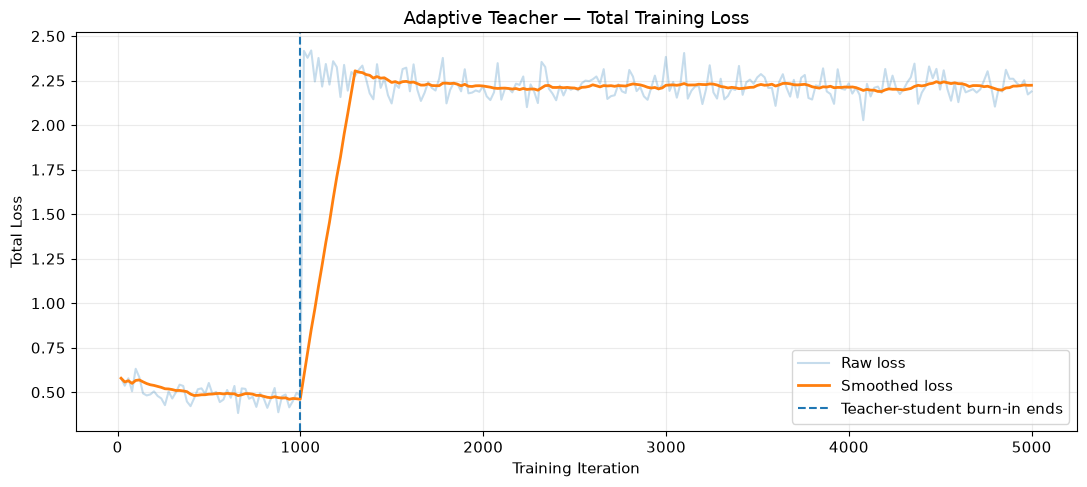

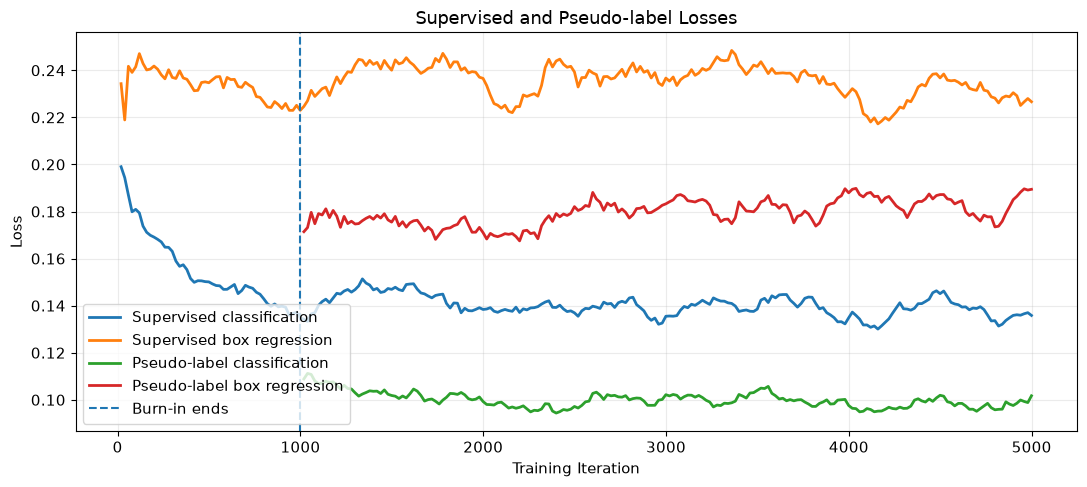

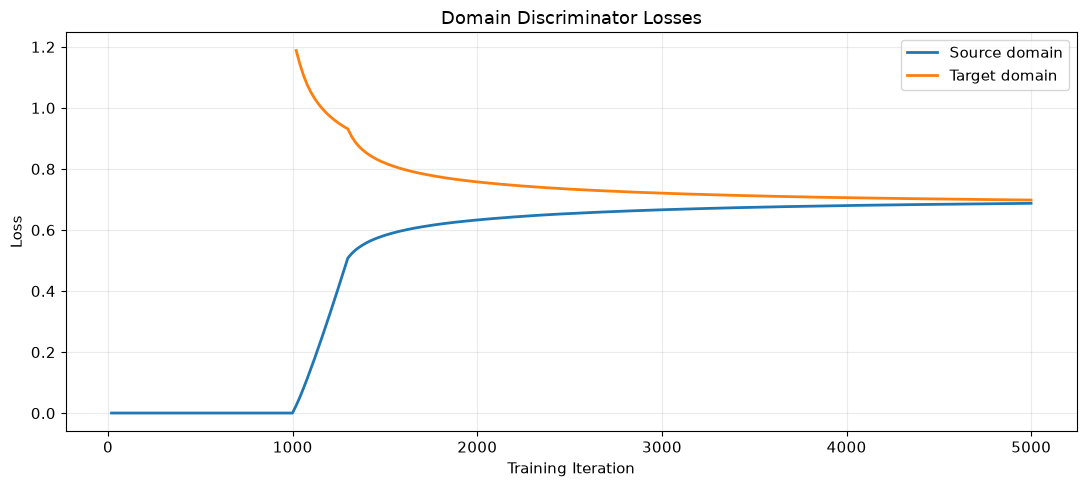


Final AP values not found in metrics.json. Training plots were saved successfully. Detection AP visualization will be available after the evaluation metrics are exported.

VISUALIZATION COMPLETE
Saved to: /workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_warmstart_v2/visualizations
  01_total_training_loss.png
  02_supervised_vs_pseudo_losses.png
  03_domain_discriminator_losses.png


In [21]:

# ============================================================
# EXPERIMENT 02 — ADAPTIVE TEACHER VISUALIZATION
# Training losses, pseudo-label losses, domain losses,
# and final object detection performance
# ============================================================

import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUN_DIR = Path(
    "/workspace/experiments/cityscapes_to_foggy/"
    "adaptive_teacher/pilot_5000_warmstart_v2"
)

LOG_FILE = RUN_DIR / "training_console.log"
METRICS_FILE = RUN_DIR / "metrics.json"
OUTPUT_DIR = RUN_DIR / "visualizations"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert LOG_FILE.exists(), f"Missing log file: {LOG_FILE}"

# ------------------------------------------------------------
# 1. Parse training metrics
# ------------------------------------------------------------

metric_names = [
    "total_loss",
    "loss_cls",
    "loss_box_reg",
    "loss_rpn_cls",
    "loss_rpn_loc",
    "loss_D_img_s",
    "loss_D_img_t",
    "loss_cls_pseudo",
    "loss_box_reg_pseudo",
    "loss_rpn_cls_pseudo",
    "loss_rpn_loc_pseudo",
    "lr",
]

rows = []

# Prefer Detectron2's structured metrics when available.
if METRICS_FILE.exists():
    for line in METRICS_FILE.read_text(
        errors="replace"
    ).splitlines():
        try:
            item = json.loads(line)
        except json.JSONDecodeError:
            continue

        if "iteration" not in item:
            continue

        row = {"iteration": item["iteration"]}

        for name in metric_names:
            row[name] = item.get(name, np.nan)

        rows.append(row)

if not rows:
    # Fallback: parse human-readable training console.
    for line in LOG_FILE.read_text(
        errors="replace"
    ).splitlines():

        match = re.search(r"\biter:\s*(\d+)", line)
        if not match or "total_loss:" not in line:
            continue

        row = {"iteration": int(match.group(1))}

        for name in metric_names:
            value = re.search(
                rf"\b{re.escape(name)}:\s*"
                r"([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)",
                line
            )
            row[name] = (
                float(value.group(1))
                if value else np.nan
            )

        rows.append(row)

df = pd.DataFrame(rows)

assert not df.empty, "No training metrics found"

df = (
    df.sort_values("iteration")
      .drop_duplicates("iteration", keep="last")
      .reset_index(drop=True)
)

df.to_csv(
    OUTPUT_DIR / "training_metrics.csv",
    index=False
)

print("Training records:", len(df))
print("Iteration range:",
      df["iteration"].min(), "to",
      df["iteration"].max())

plt.rcParams.update({
    "figure.figsize": (11, 5),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

SMOOTH_WINDOW = 15

def smooth(series):
    return series.rolling(
        window=SMOOTH_WINDOW,
        min_periods=1
    ).mean()

# ------------------------------------------------------------
# FIGURE 1 — Total training loss
# ------------------------------------------------------------

fig, ax = plt.subplots()

ax.plot(
    df["iteration"],
    df["total_loss"],
    alpha=0.25,
    label="Raw loss"
)

ax.plot(
    df["iteration"],
    smooth(df["total_loss"]),
    linewidth=2,
    label="Smoothed loss"
)

ax.axvline(
    1000,
    linestyle="--",
    label="Teacher-student burn-in ends"
)

ax.set(
    title="Adaptive Teacher — Total Training Loss",
    xlabel="Training Iteration",
    ylabel="Total Loss"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "01_total_training_loss.png",
    dpi=200
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURE 2 — Supervised vs pseudo-label losses
# ------------------------------------------------------------

fig, ax = plt.subplots()

for name, label in [
    ("loss_cls", "Supervised classification"),
    ("loss_box_reg", "Supervised box regression"),
    ("loss_cls_pseudo", "Pseudo-label classification"),
    ("loss_box_reg_pseudo", "Pseudo-label box regression"),
]:
    if name in df and df[name].notna().any():
        ax.plot(
            df["iteration"],
            smooth(df[name]),
            linewidth=2,
            label=label
        )

ax.axvline(
    1000,
    linestyle="--",
    label="Burn-in ends"
)

ax.set(
    title="Supervised and Pseudo-label Losses",
    xlabel="Training Iteration",
    ylabel="Loss"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "02_supervised_vs_pseudo_losses.png",
    dpi=200
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURE 3 — Source vs target domain losses
# ------------------------------------------------------------

fig, ax = plt.subplots()

for name, label in [
    ("loss_D_img_s", "Source domain"),
    ("loss_D_img_t", "Target domain"),
]:
    if name in df and df[name].notna().any():
        ax.plot(
            df["iteration"],
            smooth(df[name]),
            linewidth=2,
            label=label
        )

ax.set(
    title="Domain Discriminator Losses",
    xlabel="Training Iteration",
    ylabel="Loss"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "03_domain_discriminator_losses.png",
    dpi=200
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURE 4 — Final COCO AP metrics
# ------------------------------------------------------------

# Read final evaluation from metrics.json if present.
evaluation_rows = []

if METRICS_FILE.exists():
    for line in METRICS_FILE.read_text(
        errors="replace"
    ).splitlines():
        try:
            item = json.loads(line)
        except json.JSONDecodeError:
            continue

        if "bbox/AP" in item:
            evaluation_rows.append(item)

if evaluation_rows:
    final_eval = evaluation_rows[-1]

    metrics = {
        "AP": final_eval.get("bbox/AP"),
        "AP50": final_eval.get("bbox/AP50"),
        "AP75": final_eval.get("bbox/AP75"),
        "APs": final_eval.get("bbox/APs"),
        "APm": final_eval.get("bbox/APm"),
        "APl": final_eval.get("bbox/APl"),
    }

    metrics = {
        k: v for k, v in metrics.items()
        if v is not None
    }

    fig, ax = plt.subplots()

    bars = ax.bar(
        list(metrics.keys()),
        list(metrics.values())
    )

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3
    )

    ax.set(
        title="Adaptive Teacher — Final Detection Performance",
        xlabel="COCO Metric",
        ylabel="Average Precision (%)"
    )

    ax.set_ylim(
        0,
        max(metrics.values()) * 1.2
    )

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / "04_final_detection_metrics.png",
        dpi=200
    )

    plt.show()
    plt.close(fig)

    print("\nFinal evaluation metrics:")
    print(json.dumps(metrics, indent=2))

else:
    print(
        "\nFinal AP values not found in metrics.json. "
        "Training plots were saved successfully. "
        "Detection AP visualization will be available "
        "after the evaluation metrics are exported."
    )

print("\n" + "=" * 65)
print("VISUALIZATION COMPLETE")
print("=" * 65)

print("Saved to:", OUTPUT_DIR)

for path in sorted(OUTPUT_DIR.glob("*.png")):
    print(" ", path.name)
